# Homework 4: Coding

In the code spaces below, write code that answers each question. You can assume that the code spaces will all be executed in order, so any necessary libraries only need to be imported once. 

In [40]:
%pip install pylatexenc

Note: you may need to restart the kernel to use updated packages.


#### Exercise 1 
   
Refer to the `demo_two_qubit_circuits.ipynb` file and its implementation of the $\Phi^+$ state. Implement a $\Phi^-$ state and print out its state representation in braket notation. The state representation for $\Phi^-$ should look like this:

$$
\frac{\sqrt{2}}{2}|00\rangle - \frac{\sqrt{2}}{2}|11\rangle
$$

In [10]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
circuit =QuantumCircuit(2)
circuit.h(0)
circuit.cx(0,1)
circuit.z(1)
Statevector(circuit).draw('latex')


<IPython.core.display.Latex object>

#### Exercise 2
   
Implement a $\Psi^+$ state and print out its state representation in braket notation. The state representation for $\Psi^+$ should look like this:

$$
\frac{\sqrt{2}}{2}|01\rangle + \frac{\sqrt{2}}{2}|10\rangle
$$

In [11]:
circuit = QuantumCircuit(2)
circuit.x(1)
circuit.h(0)
circuit.cx(0,1)
Statevector(circuit).draw('latex')


<IPython.core.display.Latex object>

#### Exercise 3
   
Implement a $\Psi^-$ state and print out it's state representation in braket notation. The state representation for $\Psi^-$ should look like this:

$$
\frac{\sqrt{2}}{2}|01\rangle - \frac{\sqrt{2}}{2}|10\rangle
$$

In [16]:
circuit = QuantumCircuit(2)
circuit.x(1)
circuit.h(0)
circuit.cx(0,1)
circuit.z(1)
Statevector(circuit).draw('latex')

<IPython.core.display.Latex object>

#### Exercise 4
   
Run your solution to Exercise 3 on the Aer Simulator with 100 shots and report the results counts.  

In [13]:
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime import SamplerV2 as Sampler
circuit.measure_all()
sampler = Sampler(AerSimulator())
job = sampler.run([circuit], shots=100)
print(job.result()[0].data.meas.get_counts())


{'10': 53, '01': 47}


/var/folders/8y/t4fp66zs4pn5dgw11026qw580000gn/T/ipykernel_33994/1083927715.py:4: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(AerSimulator())


### Exercise 5

Run your solution to Exercise 3 on a quantum computer with 100 shots and report the results counts. Follow the steps from the HW 3 demo code to ensure that your API key is handled correctly and kept out of version control. 

In [14]:

import os
from getpass import getpass

os.environ['IBM_QUANTUM_TOKEN'] = getpass('IBM Quantum API Key: ')

In [24]:
import os
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
service = QiskitRuntimeService(channel='ibm_quantum_platform', token=os.environ['IBM_QUANTUM_TOKEN'])
backend = service.least_busy(operational=True, simulator=False)
pm=generate_preset_pass_manager(backend=backend, optimization_level=1)
sampler = Sampler(mode=backend)
job = sampler.run([pm.run(circuit)], shots=100)
print(job.result()[0].data.meas.get_counts())


qiskit_runtime_service._discover_account:WARNING:2026-11-10 17:27:45,415: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-10 17:27:47,622: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-11-10 17:27:48,073: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-11-10 17:27:50,070: Using instance: open-instance, plan: open
/var/folders/8y/t4fp66zs4pn5dgw11026qw580000gn/T/ipykernel_3

{'01': 55, '10': 43, '00': 2}


### Exercise 6

Implement a three-qubit circuit representing the W state from the lecture. This is a state with the following braket representation:

$$
\frac{1}{\sqrt{3}}|001\rangle
+\frac{1}{\sqrt{3}}|010\rangle
+\frac{1}{\sqrt{3}}|100\rangle
$$

Print out the state representation in braket notation. 

In [29]:
import math
circuit = QuantumCircuit(3)
circuit.initialize([0, 1/math.sqrt(3),1/math.sqrt(3),0,1/math.sqrt(3),0,0,0], [0,1,2])
Statevector(circuit).draw('latex')


<IPython.core.display.Latex object>

### Exercise 7

One use of the *phase kickback* phenomenon is to help to turn phase changes into measurable outcomes. 

Recall that the phase (the angle around the Z axis in the case of a single qubit on the Bloch sphere) of a qubit does not have an impact on the measurement of the qubit in the computational basis. However, as we'll see later in the course, phase is a very powerful and expressive characteristic of quantum systems. It can't be measured directly, but in the single qubit case it can be converted into a measurable amplitude with a Hadamard gate. 

We can combine this with phase kickback. Review the slides on the subject for the theoretical details and review this week's demo code for a simple setup of phase kickback. 

For this exercise, you will set up a phase-kickback circuit which results in a measurement of phase. 

The basics of the circuit are set up for you in the starter code field below. There are two qubits, `q0` and `q1` and a single classical bit `c`. We need the classical bit because we will only be measuring one of the qubits, and the way to do this in Qiskit is to project that measurement onto a classical bit. See the example of this in this week's demo code.

You will set up a phase kickback relationship between `q0` and `q1` such that a controlled phase gate of angle $\theta$ is applied which is controlled by `q0` and targeted on `q1`. You will then set up whatever operation(s) is/are necessary to put the kicked-back phase on `q0` into a measurable form. You will then measure `q0`. By doing this many times (the number of shots is set to 10000) you will get an estimate of the probability distribution over $|0\rangle$ and $|1\rangle$ outcomes. 

Remember that the probability of measuring $|0\rangle$ in terms of rotations around the X axis is $\cos^2{\frac{\theta}{2}}$. So, once you have determined a probability estimate for this outcome, you will need to invert this operation to arrive at an estimate of $\theta$.

/var/folders/8y/t4fp66zs4pn5dgw11026qw580000gn/T/ipykernel_33994/1063277663.py:12: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(backend)


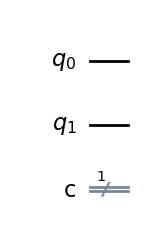

In [37]:
# Starter code. Run this first.

# Starter code. Run this first.

from qiskit import QuantumCircuit
import math
from qiskit_aer import AerSimulator

backend = AerSimulator()

from qiskit_ibm_runtime import SamplerV2 as Sampler
sampler = Sampler(backend)

circuit = QuantumCircuit(2, 1)
circuit.draw("mpl")


Phase rotation theta: 0.7853981633974483
{'0': 8518, '1': 1482}
Measured approximate phase: 0.790345284114286


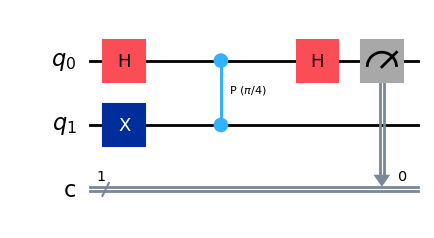

In [ ]:
# Run the starter code in the previous code space. Implement the
# necessary circuit to take advantage of phase kickback to measure
# the phase of a qubit.

# Re-running the previous circuit initializaton code to allow this
# space to run independently of the previous space.
circuit = QuantumCircuit(2, 1)

# Theta can be any angle. Experiment with several variations to ensure that
# your measurement works for arbitrary angles.
theta = math.pi/4

print(f"Phase rotation theta: {theta}")
shots = 10000

# TODO:
# Set up the phase kickback and necessary post-processing.
# Refer to this weeks demo for phase kickback basics. However,
# the kicked-back phase of q0 on its own will not be measurable.
# You will need to transform the state of q0 such that the
# rotation is put into a measurable dimension. How to do this
# is a big part of the exercise.
# Having done this, you will measure 10000 and collect
# measurement counts, which can be used as an estimate of the
# associated probabilities. Based on these values, you can
# calculate the angle between |0> and |1> of the state. This
# should match with whatever angle you set as theta above.

# Ultimately, your code should 
# re-assign this variable to be the calculated angle:
theta_meas = "<this value should be a close approximation to theta>"

### Your code begins:
circuit.h(0)
circuit.x(1)
circuit.cp(theta,0,1)
circuit.h(0)
circuit.measure(0,0)
job = sampler.run([circuit], shots=shots)
result = job.result()[0].data.c
counts = result.get_counts()
print(counts)
theta_meas=2*math.acos(math.sqrt(counts.get('0',0)/shots))
### Your code ends

# With 10000 samples you should expect to see the
# approximated phase to be within about +/- 0.02 of
# the actual value of theta most of the time.
# Re-run this code and note how the result
# changes.
print(f"Measured approximate phase: {theta_meas}")

# Drawing the circuit
circuit.draw('mpl')